In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, balanced_accuracy_score,
    roc_curve, precision_recall_curve, auc as sklearn_auc
)
from sklearn.preprocessing import Normalizer

import tensorflow as tf
from tensorflow import keras
from keras import regularizers
from keras.optimizers import Adam
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
from keras.models import load_model, Sequential
from keras.layers import Dense, Dropout

print(f"TensorFlow  : {tf.__version__}")
print(f"Keras       : {keras.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"GPUs available: {len(tf.config.list_physical_devices('GPU'))}")

TensorFlow  : 2.21.0
Keras       : 3.13.2
scikit-learn: 1.6.1
GPUs available: 0


In [3]:
METRICS = [
    keras.metrics.TruePositives(name='tp'),
    keras.metrics.FalsePositives(name='fp'),
    keras.metrics.TrueNegatives(name='tn'),
    keras.metrics.FalseNegatives(name='fn'),
    keras.metrics.BinaryAccuracy(name='accuracy'),
    keras.metrics.Precision(name='precision'),
    keras.metrics.Recall(name='recall'),
    keras.metrics.AUC(name='auc'),
    keras.metrics.AUC(name='prc', curve='PR'),
]

In [4]:
# ── Paths (Points directly to Google Drive) ──────────────────────────────────
BASE_DIR    = '/content/drive/MyDrive/MSDeepAMR'
DL_AMR_DIR  = BASE_DIR
C2018_DIR   = os.path.join(DL_AMR_DIR, 'data', 'C2018')

MODELS = {
    'e_coli_ceftriaxone'        : os.path.join(DL_AMR_DIR, 'e_coli_ceftriaxone.h5'),
    'k_pneumoniae_ceftriaxone': os.path.join(DL_AMR_DIR, 'k_pneumoniae_ceftriaxone.h5'),
    's_aureus_oxacillin'        : os.path.join(DL_AMR_DIR, 's_aureus_oxacillin.h5'),
}

# Species and drug labels must exactly match combined_long_table.csv
MODEL_META = {
    'e_coli_ceftriaxone'        : {'species': 'Escherichia coli',      'drug': 'Ceftriaxone'},
    'k_pneumoniae_ceftriaxone': {'species': 'Klebsiella pneumoniae', 'drug': 'Ceftriaxone'},
    's_aureus_oxacillin'        : {'species': 'Staphylococcus aureus',  'drug': 'Oxacillin'},
}

In [5]:
# ── Fine-tuning hyper-parameters ─────────────────────────────────────────────
LR_FULL_FINETUNE    = 1e-5   # full network, keep features alive
LR_HEAD_ONLY        = 1e-4   # fresh head on frozen CNN
LR_PARTIAL_UNFREEZE = 5e-6   # last 2 conv blocks + head

EPOCHS_FINETUNE   = 50       # fine-tuning epochs (early stopping will cut this)
BATCH_SIZE        = 10
VAL_SPLIT         = 0.1

REDUCE_LR  = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-7, verbose=0)
EARLY_STOP = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

In [6]:
# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [7]:
# ── Result store (filled progressively) ──────────────────────────────────────
ALL_RESULTS = []   # list of dicts; converted to DataFrame in the summary section

print("Configuration ready.")
for name, path in MODELS.items():
    exists = os.path.exists(path)
    print(f"  {name}: {'✓' if exists else '✗ NOT FOUND'}  ({path})")

Configuration ready.
  e_coli_ceftriaxone: ✓  (/content/drive/MyDrive/MSDeepAMR/e_coli_ceftriaxone.h5)
  k_pneumoniae_ceftriaxone: ✓  (/content/drive/MyDrive/MSDeepAMR/k_pneumoniae_ceftriaxone.h5)
  s_aureus_oxacillin: ✓  (/content/drive/MyDrive/MSDeepAMR/s_aureus_oxacillin.h5)


## Load C2018 Data

In [8]:
#BASE_DIR   = '/content/drive/MyDrive/MSDeepAMR'
#DL_AMR_DIR = BASE_DIR
#C2018_DIR  = os.path.join(BASE_DIR, 'data', 'C2018')

In [9]:
# ── Load raw arrays ───────────────────────────────────────────────────────────
raw_spectra = np.load(os.path.join(C2018_DIR, 'rawSpectra_data.npy'), allow_pickle=True)

print(f"rawSpectra_data  : {raw_spectra.shape}  dtype={raw_spectra.dtype}")

rawSpectra_data  : (9658, 6000)  dtype=float64


In [10]:
### __ Check why the label and the other dataset didn't work ___

import os

# 1. Check if Google Drive root is mounted
drive_path = '/content/drive/MyDrive'
if not os.path.exists(drive_path):
    print("❌ Google Drive is NOT mounted or path is incorrect.")
else:
    print("✅ Google Drive is mounted.")

# 2. Check each level of the directory path step-by-step
target_dir = os.path.join(drive_path, 'MSDeepAMR', 'data', 'C2018')
print(f"\nChecking directory: {target_dir}")

if os.path.exists(target_dir):
    print("✅ Target directory exists! Contents:")
    # List files in the directory to verify exact filenames
    print(os.listdir(target_dir))
else:
    print("❌ Target directory does NOT exist. Let's check what's inside 'MSDeepAMR':")
    parent_dir = os.path.join(drive_path, 'MSDeepAMR')
    if os.path.exists(parent_dir):
        print("Folders inside MSDeepAMR:", os.listdir(parent_dir))
    else:
        print("❌ 'MSDeepAMR' folder not found in MyDrive. Check capitalization or spelling.")

✅ Google Drive is mounted.

Checking directory: /content/drive/MyDrive/MSDeepAMR/data/C2018
✅ Target directory exists! Contents:
['rawSpectra_data.npy', 'maskedAE_copy10_batch50_embSize512_epoch100_MR25_data.npy', 'combined_long_table.csv', 'data_splits.csv']


In [11]:
labels_df   = pd.read_csv(os.path.join(C2018_DIR, 'combined_long_table.csv'))
print(f"combined_long    : {labels_df.shape}   columns={list(labels_df.columns)}")

combined_long    : (105646, 5)   columns=['species', 'sample_id', 'drug', 'response', 'dataset']


In [12]:
splits_df   = pd.read_csv(os.path.join(C2018_DIR, 'data_splits.csv'))

print(f"data_splits      : {splits_df.shape}   columns={list(splits_df.columns)}")
print(f"Split counts     :\n{splits_df['Set'].value_counts().to_string()}")


data_splits      : (9658, 2)   columns=['sample_id', 'Set']
Split counts     :
Set
test          5432
train         3760
validation     466


In [13]:
print(f"\nSpectra value range: [{raw_spectra.min():.4f}, {raw_spectra.max():.4f}]")
print("\nSample labels_df:")
display(labels_df.head(4))


Spectra value range: [0.0000, 0.0575]

Sample labels_df:


,species,sample_id,drug,response,dataset
0,Staphylococcus aureus,00012236-6e95-4810-b400-fa88c76c6329_MALDI1,Tetracycline,0,any
1,Staphylococcus aureus,00012236-6e95-4810-b400-fa88c76c6329_MALDI1,Clindamycin,0,any
2,Staphylococcus aureus,00012236-6e95-4810-b400-fa88c76c6329_MALDI1,Erythromycin,0,any
3,Staphylococcus aureus,00012236-6e95-4810-b400-fa88c76c6329_MALDI1,Meropenem,0,any


# Build the sample-> row index mapping

In [14]:
# The npy rows align with splits_df sorted by sample_id.
# Build a lookup: sample_id → spectrum row index.
ordered_ids    = sorted(splits_df['sample_id'].unique())
id_to_row      = {sid: i for i, sid in enumerate(ordered_ids)}

# Sanity check: number of unique IDs should equal npy rows
print(f"Unique sample IDs : {len(ordered_ids)}")
print(f"rawSpectra rows   : {raw_spectra.shape[0]}")
assert len(ordered_ids) == raw_spectra.shape[0], \
    "Mismatch! Check that rawSpectra rows align with sorted sample_ids."
print("✓  Alignment check passed.")

Unique sample IDs : 9658
rawSpectra rows   : 9658
✓  Alignment check passed.


## Build X, y arrays for a given species and drug

In [15]:
def build_splits(species: str, drug: str, verbose: bool = True):
    """
    Build train / val / test arrays from the C2018 dataset for a
    given species–drug combination.

    Returns
    -------
    X_train, y_train, X_val, y_val, X_test, y_test : numpy arrays
        Spectra are shaped (N, 6000, 1) — ready for Conv1D (channels last).
    """
    # Filter long table to this species & drug, drop NaN labels
    mask = (labels_df['species'] == species) & (labels_df['drug'] == drug)
    sub  = labels_df[mask][['sample_id', 'response']].dropna()

    # Merge with splits
    sub = sub.merge(splits_df, on='sample_id', how='inner')

    # Filter to samples that exist in our spectrum index
    sub = sub[sub['sample_id'].isin(id_to_row)].copy()
    sub['row_idx'] = sub['sample_id'].map(id_to_row)

    def get_Xy(split_name):
        rows = sub[sub['Set'] == split_name]
        X    = raw_spectra[rows['row_idx'].values].astype(np.float32)
        y    = rows['response'].values.astype(np.float32)
        # Reshape for Keras Conv1D (channels last): (N, 6000) → (N, 6000, 1)
        X    = X.reshape(X.shape[0], X.shape[1], 1)
        return X, y

    X_train, y_train = get_Xy('train')
    X_val,   y_val   = get_Xy('validation')
    X_test,  y_test  = get_Xy('test')

    if verbose:
        print(f"  Species : {species}")
        print(f"  Drug    : {drug}")
        print(f"  Train   : {X_train.shape[0]} samples | +rate={y_train.mean():.3f}")
        print(f"  Val     : {X_val.shape[0]} samples | +rate={y_val.mean():.3f}")
        print(f"  Test    : {X_test.shape[0]} samples | +rate={y_test.mean():.3f}")

    return X_train, y_train, X_val, y_val, X_test, y_test


print("build_splits() helper defined.")

build_splits() helper defined.


### We evaluate the Helper Functions just created

In [16]:
def evaluate_model(model, X_test, y_test,
                   X_train, y_train,
                   label: str = '',
                   plot: bool = True) -> dict:
    """
    Run the full evaluation suite used in the original DeepAMR notebooks.

    Parameters
    ----------
    model         : compiled Keras model
    X_test/y_test : held-out test set
    X_train/y_train : training set (used only for train prediction in ROC)
    label         : string prefix for plot titles
    plot          : whether to render plots inline

    Returns
    -------
    dict of scalar metric values for later comparison.
    """
    # ── Predictions ───────────────────────────────────────────────────────────
    test_probs  = model.predict(X_test,  batch_size=BATCH_SIZE, verbose=0)
    train_probs = model.predict(X_train, batch_size=BATCH_SIZE, verbose=0)
    y_pred      = (test_probs > 0.5).astype(int).ravel()

    # ── Confusion matrix ──────────────────────────────────────────────────────
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion matrix:")
    print(cm)

    # ── Balanced accuracy ─────────────────────────────────────────────────────
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    print(f"\nBalanced accuracy: {bal_acc:.4f}")

    # ── Classification report ─────────────────────────────────────────────────
    print("\nClassification report:")
    print(classification_report(y_test, y_pred,
                                target_names=['Susceptible (0)', 'Resistant (1)'],
                                zero_division=0))

    # ── Keras evaluate ────────────────────────────────────────────────────────
    keras_results = model.evaluate(X_test, y_test, verbose=0)
    print("Keras metrics (test set):")
    keras_dict = {}
    for name, val in zip(model.metrics_names, keras_results):
        print(f"  {name}: {val:.4f}")
        keras_dict[name] = val

    # ── AUROC & AUPRC ─────────────────────────────────────────────────────────
    fpr, tpr, _              = roc_curve(y_test, test_probs)
    roc_auc                  = sklearn_auc(fpr, tpr)
    prec_c, rec_c, _         = precision_recall_curve(y_test, test_probs)
    prc_auc                  = sklearn_auc(rec_c, prec_c)
    print(f"\nAUROC (sklearn): {roc_auc:.4f}")
    print(f"AUPRC (sklearn): {prc_auc:.4f}")

    # ── Plots ─────────────────────────────────────────────────────────────────
    if plot:
        colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        # Confusion matrix
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=['Susceptible', 'Resistant']
        ).plot(ax=axes[0], colorbar=False, cmap='Blues')
        axes[0].set_title(f'{label}\nConfusion Matrix')

        # ROC curve
        axes[1].plot(fpr, tpr, color=colors[0], linewidth=2,
                     label=f'AUROC = {roc_auc:.3f}')
        axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1)
        axes[1].set_xlabel('False positive rate')
        axes[1].set_ylabel('True positive rate')
        axes[1].set_title(f'{label}\nROC Curve')
        axes[1].legend(loc='lower right')
        axes[1].grid(True, alpha=0.3)
        axes[1].set_aspect('equal')

        # Precision-Recall curve
        baseline = y_test.mean()
        axes[2].plot(rec_c, prec_c, color=colors[0], linewidth=2,
                     label=f'AUPRC = {prc_auc:.3f}')
        axes[2].axhline(y=baseline, color='k', linestyle='--', linewidth=1,
                        label=f'No-skill ({baseline:.2f})')
        axes[2].set_xlabel('Recall')
        axes[2].set_ylabel('Precision')
        axes[2].set_title(f'{label}\nPrecision-Recall Curve')
        axes[2].legend(loc='upper right')
        axes[2].grid(True, alpha=0.3)
        axes[2].set_aspect('equal')

        plt.tight_layout()
        safe_label = label.replace(' ', '_').replace('/', '-')
        plt.savefig(f'{safe_label}_eval.png', bbox_inches='tight')
        plt.show()

    return {
        'label'       : label,
        'balanced_acc': round(bal_acc, 4),
        'accuracy'    : round(keras_dict.get('accuracy', 0), 4),
        'precision'   : round(keras_dict.get('precision', 0), 4),
        'recall'      : round(keras_dict.get('recall', 0), 4),
        'auc'         : round(keras_dict.get('auc', 0), 4),
        'prc'         : round(keras_dict.get('prc', 0), 4),
        'auroc_sk'    : round(roc_auc, 4),
        'auprc_sk'    : round(prc_auc, 4),
        'tp'          : int(keras_dict.get('tp', 0)),
        'fp'          : int(keras_dict.get('fp', 0)),
        'tn'          : int(keras_dict.get('tn', 0)),
        'fn'          : int(keras_dict.get('fn', 0)),
    }

print("evaluate_model() helper defined.")

evaluate_model() helper defined.


### We fine-tune the Helper function

In [17]:
def finetune_full(base_model_path: str, compile_metrics=None) -> keras.Model:
    """
    Strategy 1 — Full fine-tune.
    Loads model, unfreezes everything, recompiles with a small LR.
    """
    model = load_model(base_model_path)
    for layer in model.layers:
        layer.trainable = True
    model.compile(
        optimizer=Adam(learning_rate=LR_FULL_FINETUNE),
        loss='binary_crossentropy',
        metrics=compile_metrics or METRICS
    )
    print(f"Full fine-tune model — trainable layers: "
          f"{sum(1 for l in model.layers if l.trainable)} / {len(model.layers)}")
    return model

In [28]:
def finetune_frozen_cnn(base_model_path: str, compile_metrics=None) -> keras.Model:
    """
    Strategy 2 — Freeze all convolutional blocks, replace the dense head.
    Uses the Functional API to avoid Sequential input-shape duplication in Keras 3.
    """
    base  = load_model(base_model_path)
    init  = 'glorot_uniform'
    reg   = regularizers.l2(1e-4)

    # Freeze everything up to (but not including) the dense head (last 4 layers)
    n_freeze = len(base.layers) - 4
    for layer in base.layers[:n_freeze]:
        layer.trainable = False

    # Build new model using Functional API by piping inputs through the frozen trunk
    inputs = base.input
    x = inputs
    for layer in base.layers[:n_freeze]:
        x = layer(x)

    # Attach fresh dense head
    x = Dense(256, activation='relu', kernel_initializer=init, kernel_regularizer=reg, name='ft_fc0')(x)
    x = Dense(64,  activation='relu', kernel_initializer=init, kernel_regularizer=reg, name='ft_fc1')(x)
    x = Dense(64,  activation='relu', kernel_initializer=init, kernel_regularizer=reg, name='ft_fc2')(x)
    outputs = Dense(1, activation='sigmoid', name='ft_out')(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name=base.name + '_frozen_head')

    model.compile(
        optimizer=Adam(learning_rate=LR_HEAD_ONLY),
        loss='binary_crossentropy',
        metrics=compile_metrics or METRICS
    )
    trainable   = sum(1 for l in model.layers if l.trainable)
    non_trainable = len(model.layers) - trainable
    print(f"Frozen-CNN model — trainable: {trainable}  frozen: {non_trainable}")
    return model

In [29]:
def finetune_partial(base_model_path: str, compile_metrics=None) -> keras.Model:
    """
    Strategy 3 — Freeze first 2 conv blocks, unfreeze last 2 conv blocks + head.

    Layer layout of the pretrained models (by index):
        0  Conv_1
        1  BatchNorm
        2  Activation
        3  MaxPooling1D
        4  Conv_2
        5  BatchNorm
        6  Activation
        7  MaxPooling1D1
        8  Conv_3          <- unfreeze from here
        9  BatchNorm
        10 Activation
        11 MaxPooling1D2
        12 Conv_3l / Conv_4
        13 BatchNorm
        14 Activation
        15 MaxPooling1D2dl
        16 Flatten
        17 Dropout
        18 Dense(256)
        19 Dense(64)
        20 Dense(64)
        21 Dense(1)
    """
    model         = load_model(base_model_path)
    FREEZE_UNTIL  = 8   # freeze layers 0–7 (first 2 conv blocks)

    for i, layer in enumerate(model.layers):
        layer.trainable = (i >= FREEZE_UNTIL)

    model.compile(
        optimizer=Adam(learning_rate=LR_PARTIAL_UNFREEZE),
        loss='binary_crossentropy',
        metrics=compile_metrics or METRICS
    )
    trainable = sum(1 for l in model.layers if l.trainable)
    frozen    = len(model.layers) - trainable
    print(f"Partial-unfreeze model — trainable: {trainable}  frozen: {frozen}")
    return model

In [30]:
def run_finetune(model, X_train, y_train, X_val, y_val):
    """
    Run model.fit with the standard callbacks and return the history object.
    Combines train + val internally when validation data is provided explicitly.
    """
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS_FINETUNE,
        batch_size=BATCH_SIZE,
        verbose=1,
        validation_data=(X_val, y_val),
        callbacks=[REDUCE_LR, EARLY_STOP]
    )
    return history


print("Fine-tuning helpers defined.")

Fine-tuning helpers defined.


## Learning Curve Helper review

In [31]:
def plot_history(history, label: str = ''):
    """Plot loss and accuracy learning curves from a Keras History object."""
    h      = history.history
    epochs = range(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs, h['loss'],     label='train loss')
    axes[0].plot(epochs, h['val_loss'], label='val loss')
    axes[0].set_title(f'{label} — Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Binary cross-entropy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    acc_key = 'accuracy' if 'accuracy' in h else 'binary_accuracy'
    axes[1].plot(epochs, h[acc_key],         label='train acc')
    axes[1].plot(epochs, h[f'val_{acc_key}'], label='val acc')
    axes[1].set_title(f'{label} — Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle(label, fontsize=13)
    plt.tight_layout()
    safe = label.replace(' ', '_').replace('/', '-')
    plt.savefig(f'{safe}_curves.png', bbox_inches='tight')
    plt.show()

print("plot_history() helper defined.")

plot_history() helper defined.


# The Experiment Layers

In [32]:
# E. coli /Ceftriaxone
print("=" * 60)
print("ORGANISM : Escherichia coli")
print("DRUG     : Ceftriaxone")
print("=" * 60)

EC_META = MODEL_META['e_coli_ceftriaxone']
X_train_ec, y_train_ec, X_val_ec, y_val_ec, X_test_ec, y_test_ec = \
    build_splits(EC_META['species'], EC_META['drug'])

ORGANISM : Escherichia coli
DRUG     : Ceftriaxone
  Species : Escherichia coli
  Drug    : Ceftriaxone
  Train   : 737 samples | +rate=0.163
  Val     : 92 samples | +rate=0.207
  Test    : 780 samples | +rate=0.104


In [23]:
import os

# Check if DL-AMR folder exists locally
print("Checking /content/DL-AMR:")
if os.path.exists('/content/DL-AMR'):
    print("✅ Folder exists! Contents:", os.listdir('/content/DL-AMR'))
else:
    print("❌ /content/DL-AMR does NOT exist locally.")

# Check if it's supposed to be in Google Drive
drive_models_path = '/content/drive/MyDrive/MSDeepAMR' # Adjust if your folder name differs
print(f"\nChecking Google Drive path ({drive_models_path}):")
if os.path.exists(drive_models_path):
    print("✅ Drive path exists! Contents:", os.listdir(drive_models_path))
else:
    print("❌ Drive path not found.")

Checking /content/DL-AMR:
❌ /content/DL-AMR does NOT exist locally.

Checking Google Drive path (/content/drive/MyDrive/MSDeepAMR):
✅ Drive path exists! Contents: ['README.md', 'data', 'e_coli_ceftriaxone.h5', 'k_pneumoniae_ceftriaxone.h5', 's_aureus_oxacillin.h5']


Model: "Modelo_e_coli_ceftriaxone"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv_1 (Conv1D)                 │ (None, 5985, 64)       │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 5985, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 5985, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D (MaxPooling1D)     │ (None, 2992, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv1D)                 │ (None, 2984, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 2984, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 2984, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D1 (MaxPooling1D)    │ (None, 1492, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3 (Conv1D)                 │ (None, 1488, 256)      │       164,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 1488, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 1488, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D2 (MaxPooling1D)    │ (None, 744, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3l (Conv1D)                │ (None, 740, 256)       │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 740, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 740, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D2dl (MaxPooling1D)  │ (None, 370, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 94720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 94720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_0 (Dense)       │ (None, 256)            │    24,248,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_1 (Dense)       │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_2 (Dense)       │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ OUT_Layer (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,839,105 (94.75 MB)

 Trainable params: 24,837,697 (94.75 MB)

 Non-trainable params: 1,408 (5.50 KB)


--- Experiment 6-A: Baseline (zero-shot) ---
Confusion matrix:
[[699   0]
 [ 81   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.90      1.00      0.95       699
  Resistant (1)       0.00      0.00      0.00        81

       accuracy                           0.90       780
      macro avg       0.45      0.50      0.47       780
   weighted avg       0.80      0.90      0.85       780

Keras metrics (test set):
  loss: 0.7291
  compile_metrics: 5.0000

AUROC (sklearn): 0.6273
AUPRC (sklearn): 0.1784


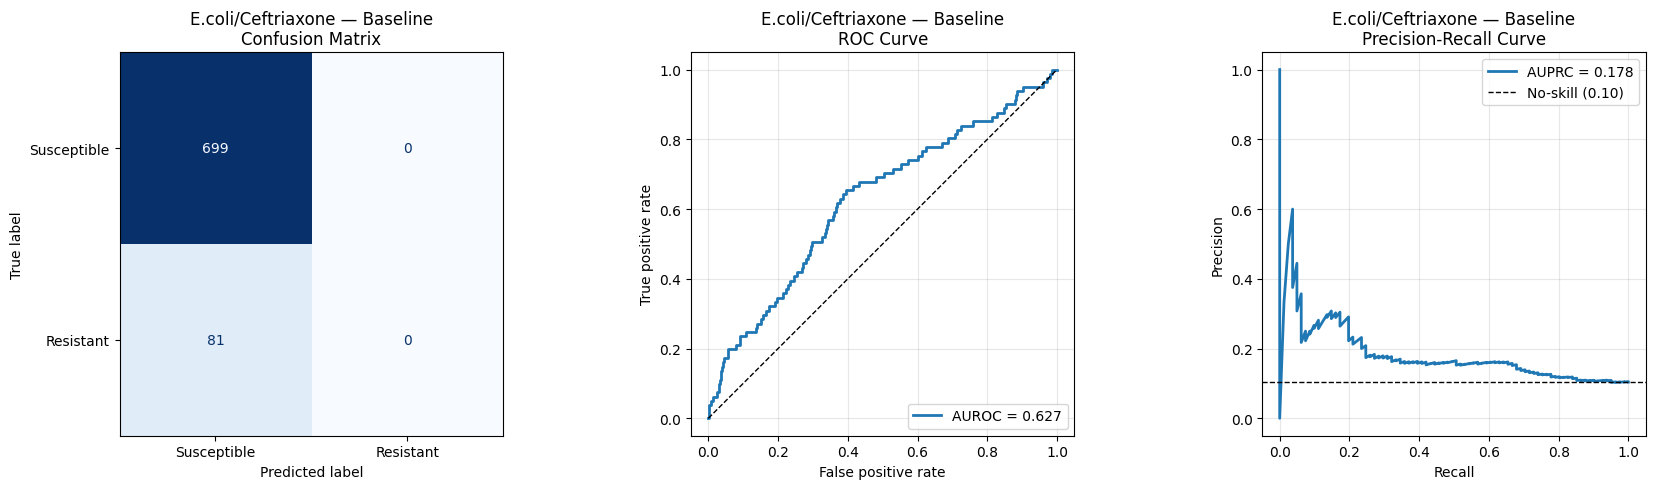

In [33]:
## Baseline --- Zero-shot on C2018 test set
ec_model_base = load_model(MODELS['e_coli_ceftriaxone'])
ec_model_base.compile(optimizer=Adam(1e-4), loss='binary_crossentropy', metrics=METRICS)
ec_model_base.summary()

print("\n--- Experiment 6-A: Baseline (zero-shot) ---")
res = evaluate_model(ec_model_base, X_test_ec, y_test_ec,
                     X_train_ec, y_train_ec,
                     label='E.coli/Ceftriaxone — Baseline')
res['model'] = 'e_coli_ceftriaxone'; res['experiment'] = 'Baseline'
ALL_RESULTS.append(res)

--- Experiment 6-B: Full fine-tune ---


Full fine-tune model — trainable layers: 22 / 22
Epoch 1/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.8637 - auc: 0.6184 - fn: 241.0000 - fp: 72.0000 - loss: 1.1663 - prc: 0.2303 - precision: 0.3628 - recall: 0.1454 - tn: 1943.0000 - tp: 41.0000 - val_accuracy: 0.7935 - val_auc: 0.5411 - val_fn: 19.0000 - val_fp: 0.0000e+00 - val_loss: 0.9532 - val_prc: 0.3121 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 73.0000 - val_tp: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.8290 - auc: 0.6835 - fn: 84.0000 - fp: 42.0000 - loss: 0.9945 - prc: 0.3439 - precision: 0.4615 - recall: 0.3000 - tn: 575.0000 - tp: 36.0000 - val_accuracy: 0.7935 - val_auc: 0.5573 - val_fn: 19.0000 - val_fp: 0.0000e+00 - val_loss: 0.9190 - val_prc: 0.3392 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 73.0000 - val_tp: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 3/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy

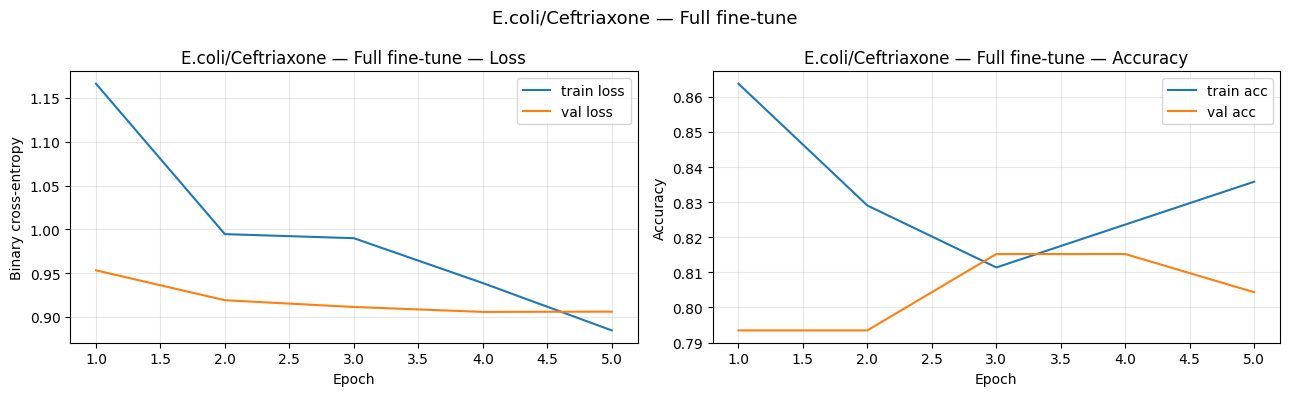

Confusion matrix:
[[699   0]
 [ 81   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.90      1.00      0.95       699
  Resistant (1)       0.00      0.00      0.00        81

       accuracy                           0.90       780
      macro avg       0.45      0.50      0.47       780
   weighted avg       0.80      0.90      0.85       780

Keras metrics (test set):
  loss: 0.7290
  compile_metrics: 0.0000

AUROC (sklearn): 0.6323
AUPRC (sklearn): 0.1881


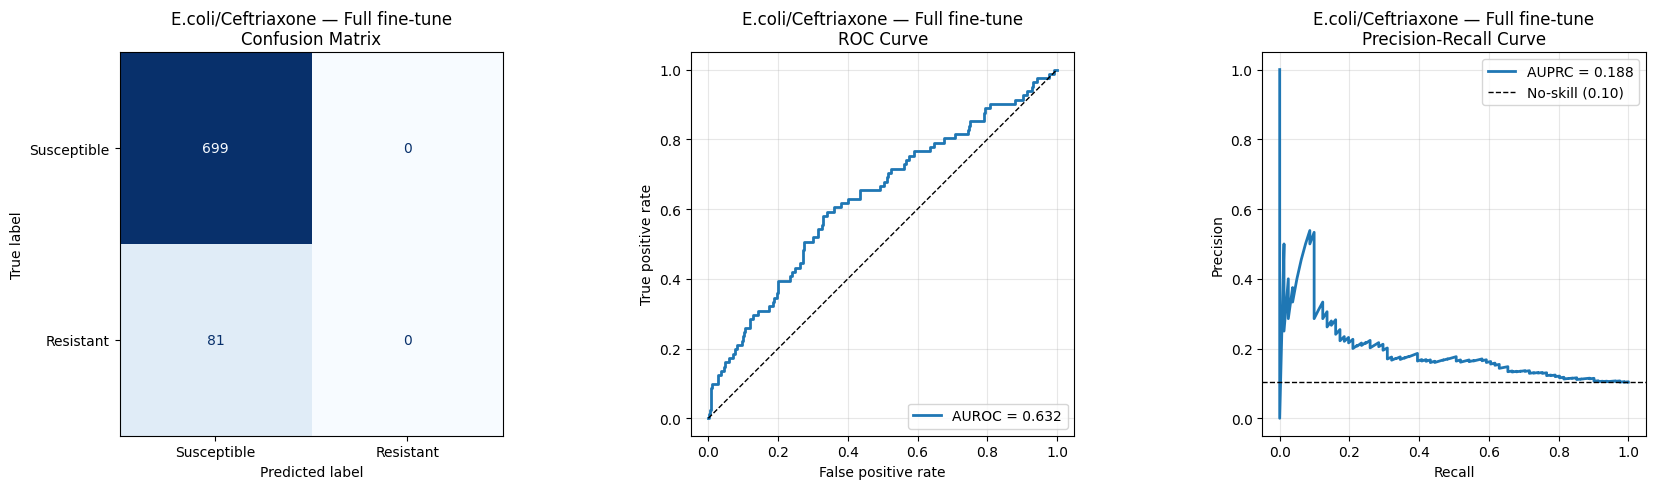

Saved: e_coli_ceftriaxone_finetuned_full.h5


In [35]:
# Full time Fine-tuning
print("--- Experiment 6-B: Full fine-tune ---")
ec_ft_full = finetune_full(MODELS['e_coli_ceftriaxone'])
hist_ec_full = run_finetune(ec_ft_full, X_train_ec, y_train_ec, X_val_ec, y_val_ec)
plot_history(hist_ec_full, label='E.coli/Ceftriaxone — Full fine-tune')

res = evaluate_model(ec_ft_full, X_test_ec, y_test_ec,
                     X_train_ec, y_train_ec,
                     label='E.coli/Ceftriaxone — Full fine-tune')
res['model'] = 'e_coli_ceftriaxone'; res['experiment'] = 'Full fine-tune'
ALL_RESULTS.append(res)

ec_ft_full.save('e_coli_ceftriaxone_finetuned_full.h5')
print("Saved: e_coli_ceftriaxone_finetuned_full.h5")

--- Experiment 6-D: Partial unfreeze ---


Partial-unfreeze model — trainable: 14  frozen: 8
Epoch 1/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.8352 - auc: 0.6055 - fn: 160.0000 - fp: 90.0000 - loss: 1.2560 - prc: 0.2389 - precision: 0.3130 - recall: 0.2040 - tn: 1226.0000 - tp: 41.0000 - val_accuracy: 0.7935 - val_auc: 0.5454 - val_fn: 19.0000 - val_fp: 0.0000e+00 - val_loss: 0.8927 - val_prc: 0.2950 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 73.0000 - val_tp: 0.0000e+00 - learning_rate: 5.0000e-06
Epoch 2/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.7856 - auc: 0.6226 - fn: 89.0000 - fp: 69.0000 - loss: 1.1774 - prc: 0.3057 - precision: 0.3100 - recall: 0.2583 - tn: 548.0000 - tp: 31.0000 - val_accuracy: 0.8043 - val_auc: 0.5472 - val_fn: 17.0000 - val_fp: 1.0000 - val_loss: 0.8955 - val_prc: 0.2903 - val_precision: 0.6667 - val_recall: 0.1053 - val_tn: 72.0000 - val_tp: 2.0000 - learning_rate: 5.0000e-06
Epoch 3/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.8087 - auc: 0

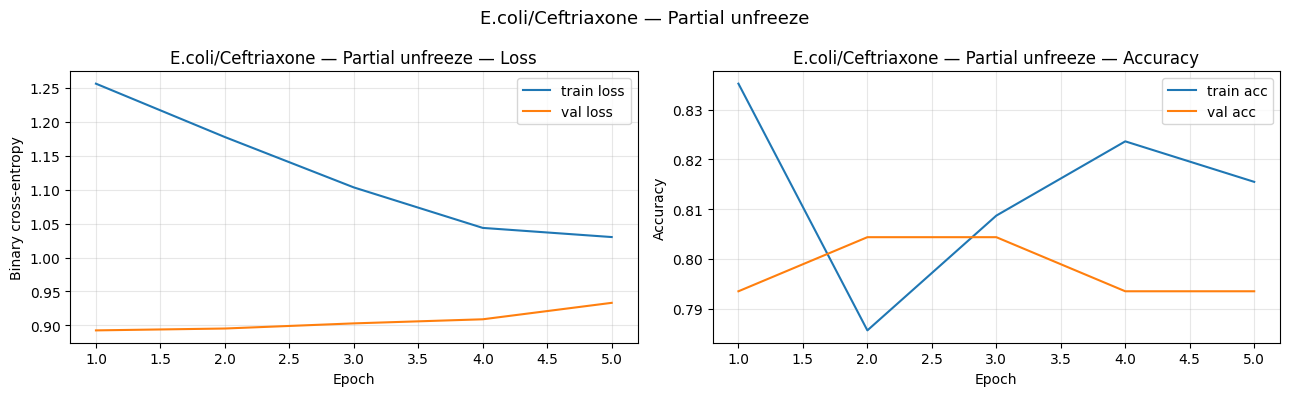

Confusion matrix:
[[699   0]
 [ 81   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.90      1.00      0.95       699
  Resistant (1)       0.00      0.00      0.00        81

       accuracy                           0.90       780
      macro avg       0.45      0.50      0.47       780
   weighted avg       0.80      0.90      0.85       780

Keras metrics (test set):
  loss: 0.7152
  compile_metrics: 0.0000

AUROC (sklearn): 0.6301
AUPRC (sklearn): 0.1878


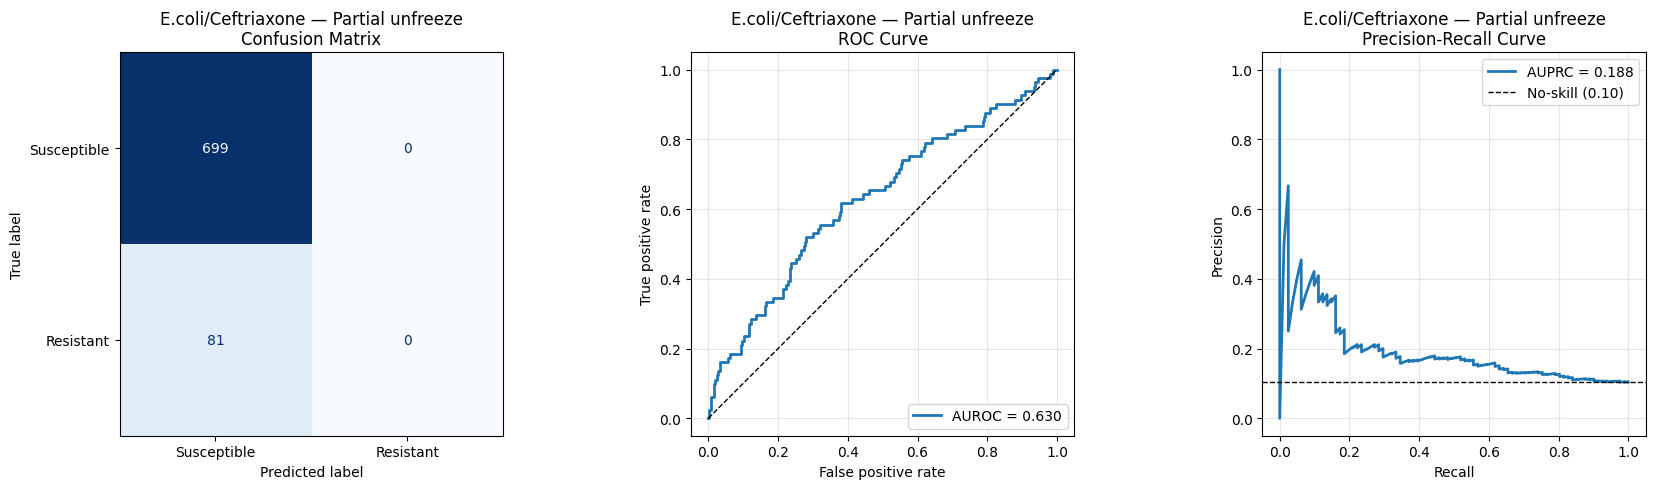

Saved: e_coli_ceftriaxone_finetuned_partial.h5


In [37]:
## Partial Unfreeze (last 2 conv blocks + head)
print("--- Experiment 6-D: Partial unfreeze ---")
ec_ft_partial = finetune_partial(MODELS['e_coli_ceftriaxone'])
hist_ec_partial = run_finetune(ec_ft_partial, X_train_ec, y_train_ec, X_val_ec, y_val_ec)
plot_history(hist_ec_partial, label='E.coli/Ceftriaxone — Partial unfreeze')

res = evaluate_model(ec_ft_partial, X_test_ec, y_test_ec,
                     X_train_ec, y_train_ec,
                     label='E.coli/Ceftriaxone — Partial unfreeze')
res['model'] = 'e_coli_ceftriaxone'; res['experiment'] = 'Partial unfreeze'
ALL_RESULTS.append(res)

ec_ft_partial.save('e_coli_ceftriaxone_finetuned_partial.h5')
print("Saved: e_coli_ceftriaxone_finetuned_partial.h5")

## Experiment Block - K. Pneumoniae/ Ceftriaxone

In [38]:
print("=" * 60)
print("ORGANISM : Klebsiella pneumoniae")
print("DRUG     : Ceftriaxone")
print("=" * 60)

KP_META = MODEL_META['k_pneumoniae_ceftriaxone']
X_train_kp, y_train_kp, X_val_kp, y_val_kp, X_test_kp, y_test_kp = \
    build_splits(KP_META['species'], KP_META['drug'])

ORGANISM : Klebsiella pneumoniae
DRUG     : Ceftriaxone
  Species : Klebsiella pneumoniae
  Drug    : Ceftriaxone
  Train   : 297 samples | +rate=0.152
  Val     : 40 samples | +rate=0.150
  Test    : 526 samples | +rate=0.065


Model: "Modelo_k_pneumoniae_ceftriaxone"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv_1 (Conv1D)                 │ (None, 5985, 64)       │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 5985, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 5985, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D (MaxPooling1D)     │ (None, 2992, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv1D)                 │ (None, 2984, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 2984, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 2984, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D1 (MaxPooling1D)    │ (None, 1492, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3 (Conv1D)                 │ (None, 1488, 256)      │       164,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 1488, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 1488, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D2 (MaxPooling1D)    │ (None, 744, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3l (Conv1D)                │ (None, 740, 256)       │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 740, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 740, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D2dl (MaxPooling1D)  │ (None, 370, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 94720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 94720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_0 (Dense)       │ (None, 256)            │    24,248,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_1 (Dense)       │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_2 (Dense)       │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ OUT_Layer (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,839,105 (94.75 MB)

 Trainable params: 24,837,697 (94.75 MB)

 Non-trainable params: 1,408 (5.50 KB)


--- Experiment 7-A: Baseline (zero-shot) ---
Confusion matrix:
[[492   0]
 [ 34   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.94      1.00      0.97       492
  Resistant (1)       0.00      0.00      0.00        34

       accuracy                           0.94       526
      macro avg       0.47      0.50      0.48       526
   weighted avg       0.87      0.94      0.90       526

Keras metrics (test set):
  loss: 0.5069
  compile_metrics: 0.0000

AUROC (sklearn): 0.6995
AUPRC (sklearn): 0.1813


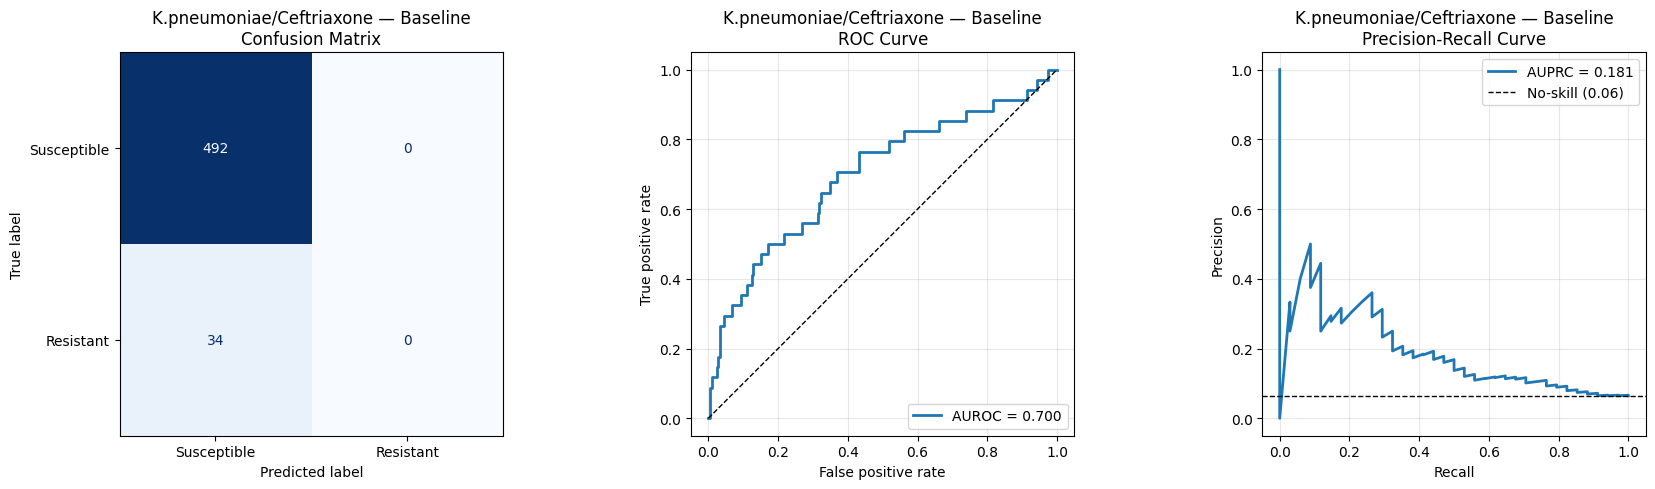

In [39]:
## Baseline -- Zero-shot
kp_model_base = load_model(MODELS['k_pneumoniae_ceftriaxone'])
kp_model_base.compile(optimizer=Adam(1e-4), loss='binary_crossentropy', metrics=METRICS)
kp_model_base.summary()

print("\n--- Experiment 7-A: Baseline (zero-shot) ---")
res = evaluate_model(kp_model_base, X_test_kp, y_test_kp,
                     X_train_kp, y_train_kp,
                     label='K.pneumoniae/Ceftriaxone — Baseline')
res['model'] = 'k_pneumoniae_ceftriaxone'; res['experiment'] = 'Baseline'
ALL_RESULTS.append(res)

--- Experiment 7-B: Full fine-tune ---


Full fine-tune model — trainable layers: 22 / 22
Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.8690 - auc: 0.5482 - fn: 146.0000 - fp: 64.0000 - loss: 0.9232 - prc: 0.1344 - precision: 0.1795 - recall: 0.0875 - tn: 1379.0000 - tp: 14.0000 - val_accuracy: 0.8500 - val_auc: 0.7377 - val_fn: 6.0000 - val_fp: 0.0000e+00 - val_loss: 0.6058 - val_prc: 0.3130 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 34.0000 - val_tp: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.6801 - auc: 0.5266 - fn: 36.0000 - fp: 59.0000 - loss: 0.8520 - prc: 0.1577 - precision: 0.1324 - recall: 0.2000 - tn: 193.0000 - tp: 9.0000 - val_accuracy: 0.8500 - val_auc: 0.7304 - val_fn: 6.0000 - val_fp: 0.0000e+00 - val_loss: 0.6188 - val_prc: 0.2815 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 34.0000 - val_tp: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.73

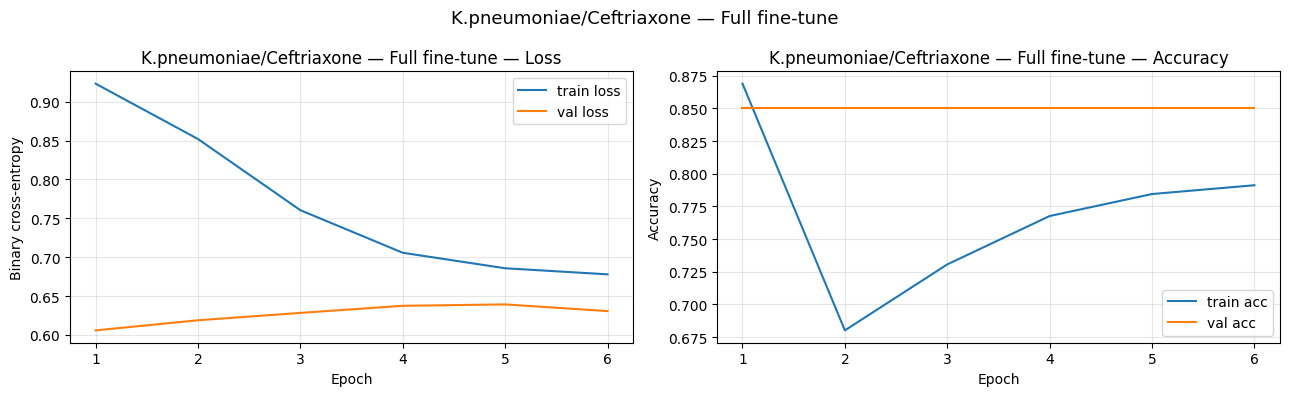

Confusion matrix:
[[492   0]
 [ 34   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.94      1.00      0.97       492
  Resistant (1)       0.00      0.00      0.00        34

       accuracy                           0.94       526
      macro avg       0.47      0.50      0.48       526
   weighted avg       0.87      0.94      0.90       526

Keras metrics (test set):
  loss: 0.5245
  compile_metrics: 0.0000

AUROC (sklearn): 0.6955
AUPRC (sklearn): 0.1889


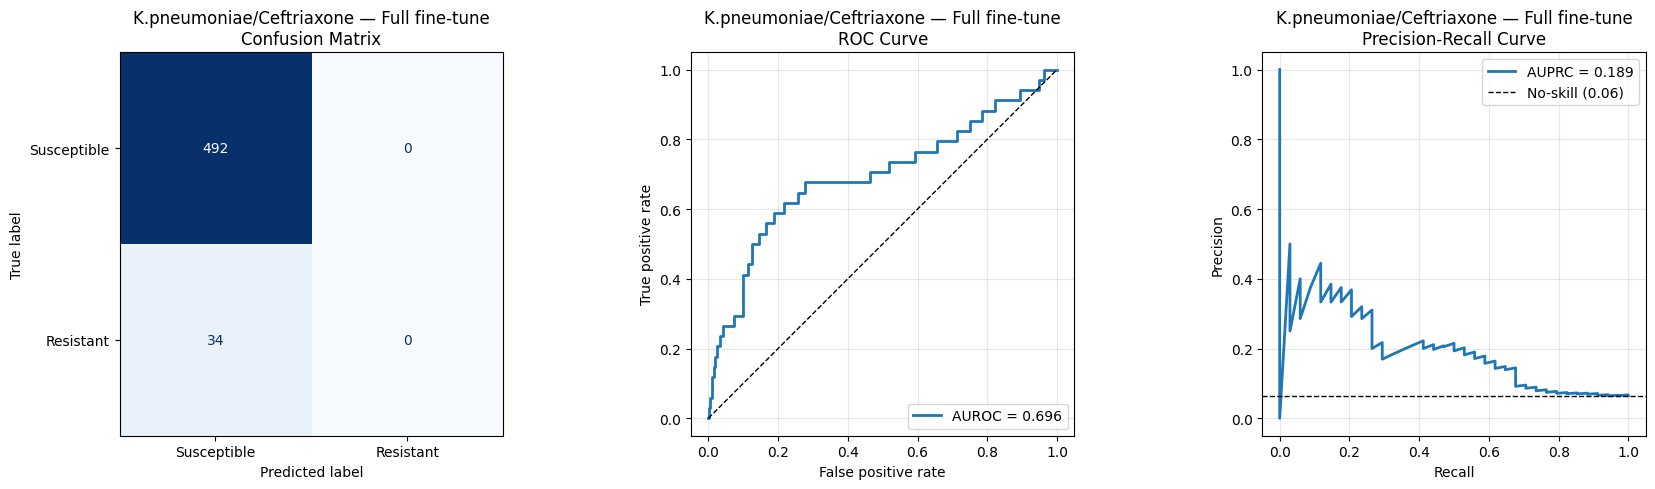

Saved: k_pneumoniae_ceftriaxone_finetuned_full.h5


In [40]:
## Full Fine-tune
print("--- Experiment 7-B: Full fine-tune ---")
kp_ft_full = finetune_full(MODELS['k_pneumoniae_ceftriaxone'])
hist_kp_full = run_finetune(kp_ft_full, X_train_kp, y_train_kp, X_val_kp, y_val_kp)
plot_history(hist_kp_full, label='K.pneumoniae/Ceftriaxone — Full fine-tune')

res = evaluate_model(kp_ft_full, X_test_kp, y_test_kp,
                     X_train_kp, y_train_kp,
                     label='K.pneumoniae/Ceftriaxone — Full fine-tune')
res['model'] = 'k_pneumoniae_ceftriaxone'; res['experiment'] = 'Full fine-tune'
ALL_RESULTS.append(res)

kp_ft_full.save('k_pneumoniae_ceftriaxone_finetuned_full.h5')
print("Saved: k_pneumoniae_ceftriaxone_finetuned_full.h5")

--- Experiment 7-D: Partial unfreeze ---


Partial-unfreeze model — trainable: 14  frozen: 8
Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.8299 - auc: 0.5468 - fn: 64.0000 - fp: 76.0000 - loss: 0.9496 - prc: 0.1255 - precision: 0.1648 - recall: 0.1899 - tn: 668.0000 - tp: 15.0000 - val_accuracy: 0.8500 - val_auc: 0.7230 - val_fn: 6.0000 - val_fp: 0.0000e+00 - val_loss: 0.6200 - val_prc: 0.2836 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 34.0000 - val_tp: 0.0000e+00 - learning_rate: 5.0000e-06
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.6532 - auc: 0.4934 - fn: 35.0000 - fp: 68.0000 - loss: 0.9693 - prc: 0.1644 - precision: 0.1282 - recall: 0.2222 - tn: 184.0000 - tp: 10.0000 - val_accuracy: 0.8500 - val_auc: 0.7426 - val_fn: 6.0000 - val_fp: 0.0000e+00 - val_loss: 0.6443 - val_prc: 0.2875 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 34.0000 - val_tp: 0.0000e+00 - learning_rate: 5.0000e-06
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.67

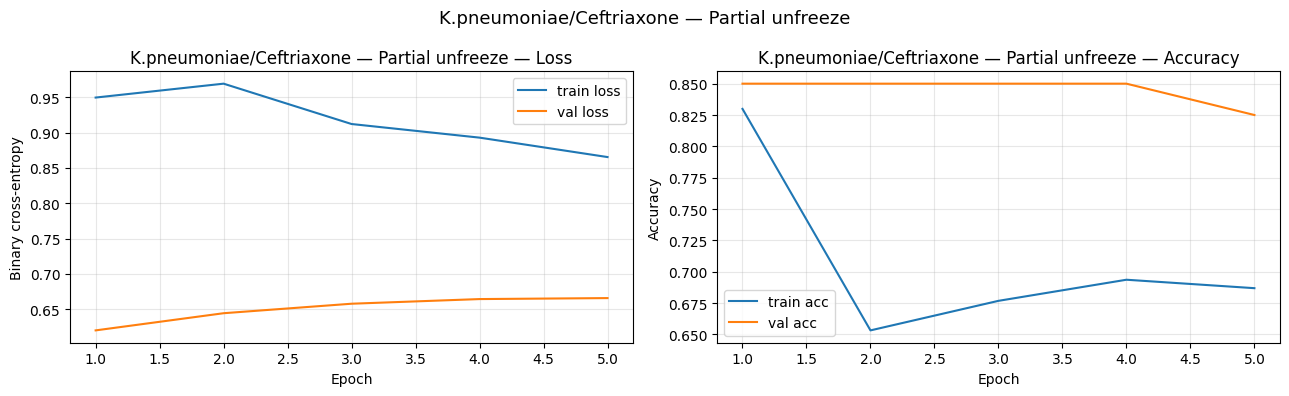

Confusion matrix:
[[492   0]
 [ 34   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.94      1.00      0.97       492
  Resistant (1)       0.00      0.00      0.00        34

       accuracy                           0.94       526
      macro avg       0.47      0.50      0.48       526
   weighted avg       0.87      0.94      0.90       526

Keras metrics (test set):
  loss: 0.5486
  compile_metrics: 0.0000

AUROC (sklearn): 0.6897
AUPRC (sklearn): 0.1810


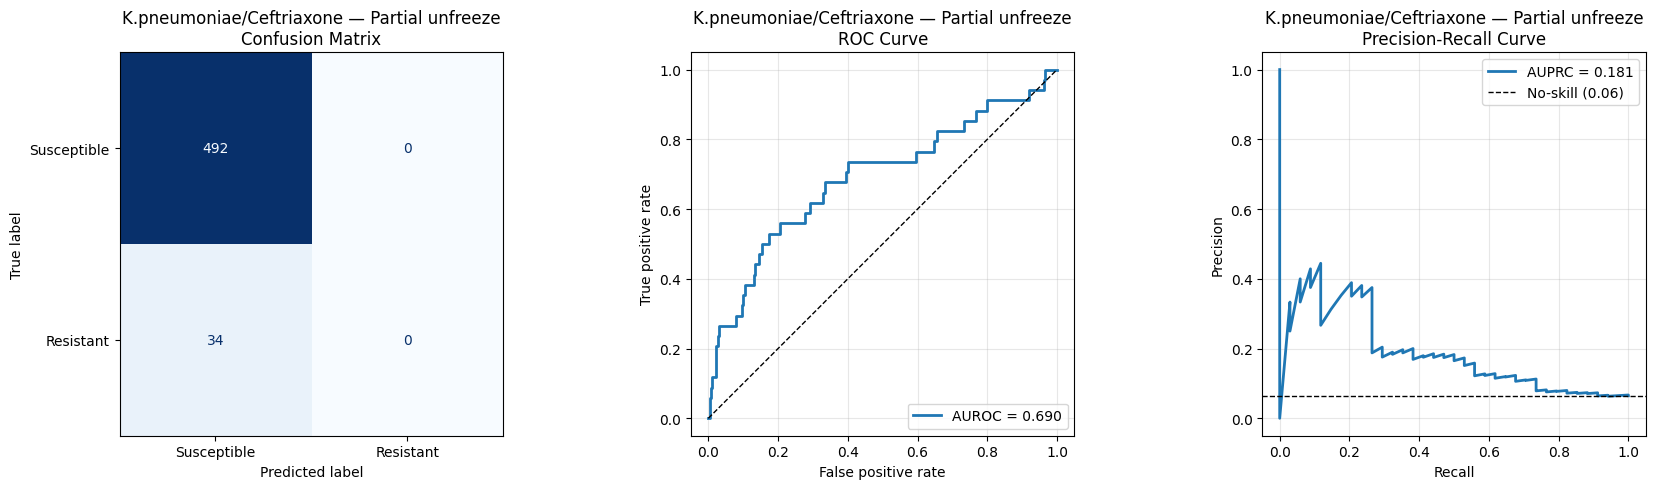

Saved: k_pneumoniae_ceftriaxone_finetuned_partial.h5


In [42]:
## Partial Unfreeze
print("--- Experiment 7-D: Partial unfreeze ---")
kp_ft_partial = finetune_partial(MODELS['k_pneumoniae_ceftriaxone'])
hist_kp_partial = run_finetune(kp_ft_partial, X_train_kp, y_train_kp, X_val_kp, y_val_kp)
plot_history(hist_kp_partial, label='K.pneumoniae/Ceftriaxone — Partial unfreeze')

res = evaluate_model(kp_ft_partial, X_test_kp, y_test_kp,
                     X_train_kp, y_train_kp,
                     label='K.pneumoniae/Ceftriaxone — Partial unfreeze')
res['model'] = 'k_pneumoniae_ceftriaxone'; res['experiment'] = 'Partial unfreeze'
ALL_RESULTS.append(res)

kp_ft_partial.save('k_pneumoniae_ceftriaxone_finetuned_partial.h5')
print("Saved: k_pneumoniae_ceftriaxone_finetuned_partial.h5")

Experiment Block - S. Aureus/Oxacillin

In [43]:
print("=" * 60)
print("ORGANISM : Staphylococcus aureus")
print("DRUG     : Oxacillin")
print("=" * 60)

SA_META = MODEL_META['s_aureus_oxacillin']
X_train_sa, y_train_sa, X_val_sa, y_val_sa, X_test_sa, y_test_sa = \
    build_splits(SA_META['species'], SA_META['drug'])

ORGANISM : Staphylococcus aureus
DRUG     : Oxacillin
  Species : Staphylococcus aureus
  Drug    : Oxacillin
  Train   : 573 samples | +rate=0.061
  Val     : 83 samples | +rate=0.024
  Test    : 450 samples | +rate=0.082


Model: "Modelo_s_aureus_oxacillin"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv_1 (Conv1D)                 │ (None, 5985, 64)       │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 5985, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 5985, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D (MaxPooling1D)     │ (None, 2992, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv1D)                 │ (None, 2984, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 2984, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 2984, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D1 (MaxPooling1D)    │ (None, 1492, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3 (Conv1D)                 │ (None, 1488, 256)      │       164,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 1488, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 1488, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D2 (MaxPooling1D)    │ (None, 744, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3l (Conv1D)                │ (None, 740, 256)       │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 740, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 740, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D2dl (MaxPooling1D)  │ (None, 370, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 94720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 94720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_0 (Dense)       │ (None, 256)            │    24,248,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_1 (Dense)       │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_2 (Dense)       │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ OUT_Layer (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,839,105 (94.75 MB)

 Trainable params: 24,837,697 (94.75 MB)

 Non-trainable params: 1,408 (5.50 KB)


--- Experiment 8-A: Baseline (zero-shot) ---
Confusion matrix:
[[403  10]
 [ 36   1]]

Balanced accuracy: 0.5014

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.92      0.98      0.95       413
  Resistant (1)       0.09      0.03      0.04        37

       accuracy                           0.90       450
      macro avg       0.50      0.50      0.49       450
   weighted avg       0.85      0.90      0.87       450

Keras metrics (test set):
  loss: 1.0834
  compile_metrics: 1.0000

AUROC (sklearn): 0.7032
AUPRC (sklearn): 0.1272


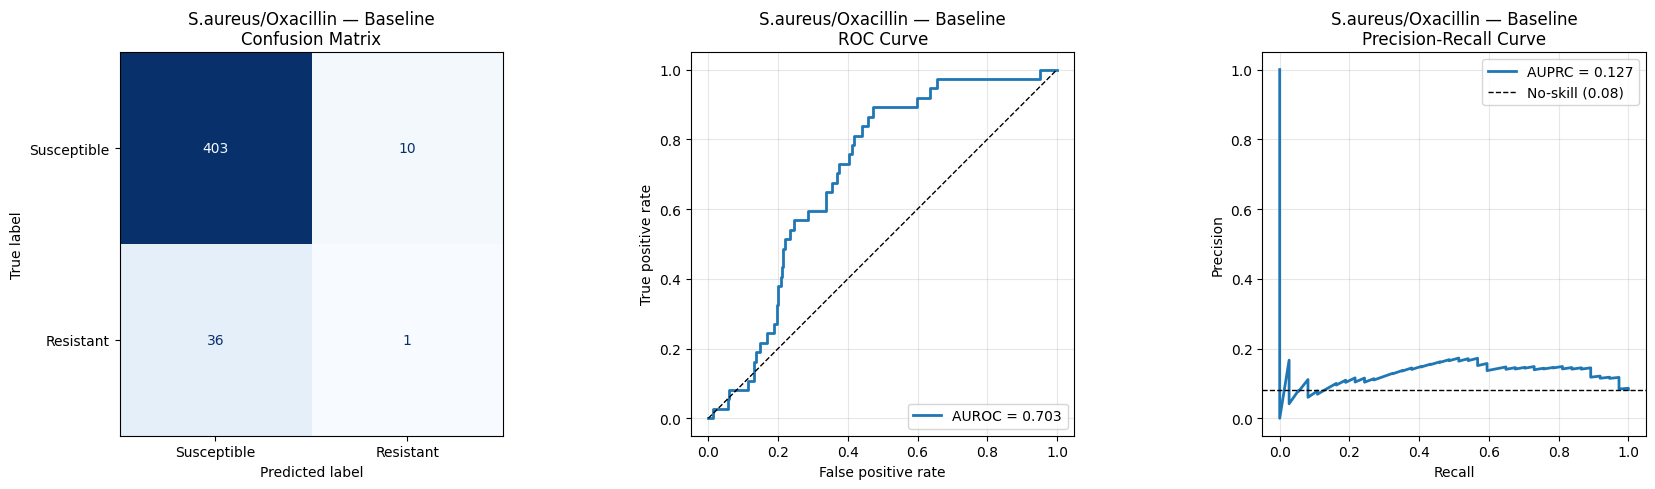

In [44]:
## Baseline -- Zero-shot
sa_model_base = load_model(MODELS['s_aureus_oxacillin'])
sa_model_base.compile(optimizer=Adam(1e-4), loss='binary_crossentropy', metrics=METRICS)
sa_model_base.summary()

print("\n--- Experiment 8-A: Baseline (zero-shot) ---")
res = evaluate_model(sa_model_base, X_test_sa, y_test_sa,
                     X_train_sa, y_train_sa,
                     label='S.aureus/Oxacillin — Baseline')
res['model'] = 's_aureus_oxacillin'; res['experiment'] = 'Baseline'
ALL_RESULTS.append(res)

--- Experiment 8-B: Full fine-tune ---


Full fine-tune model — trainable layers: 22 / 22
Epoch 1/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.8909 - auc: 0.6210 - fn: 95.0000 - fp: 74.0000 - loss: 1.0312 - prc: 0.1183 - precision: 0.1294 - recall: 0.1038 - tn: 1369.0000 - tp: 11.0000 - val_accuracy: 0.9759 - val_auc: 0.1543 - val_fn: 2.0000 - val_fp: 0.0000e+00 - val_loss: 0.8129 - val_prc: 0.0136 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 81.0000 - val_tp: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.9127 - auc: 0.6305 - fn: 32.0000 - fp: 18.0000 - loss: 0.8719 - prc: 0.1111 - precision: 0.1429 - recall: 0.0857 - tn: 520.0000 - tp: 3.0000 - val_accuracy: 0.9398 - val_auc: 0.0525 - val_fn: 2.0000 - val_fp: 3.0000 - val_loss: 0.7754 - val_prc: 0.0126 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 78.0000 - val_tp: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 3/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.9145

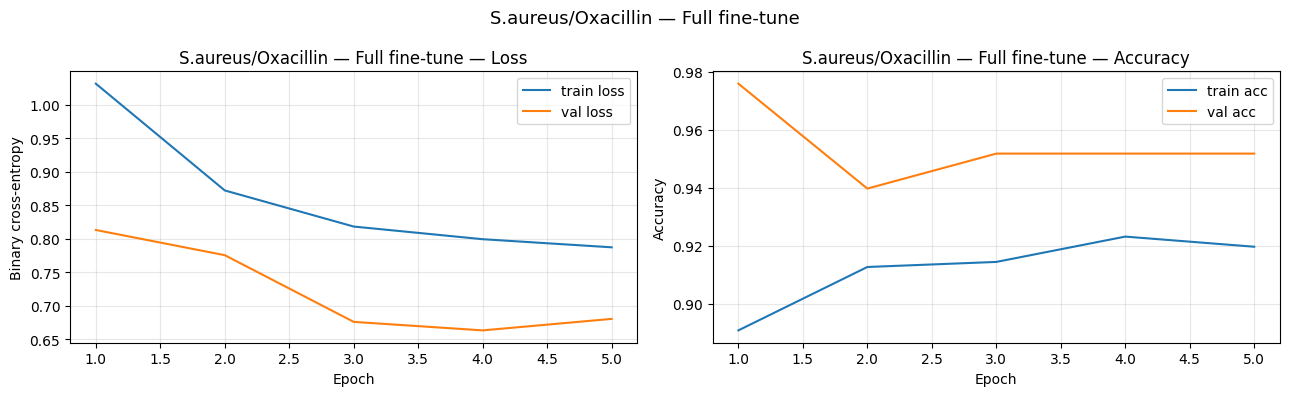

Confusion matrix:
[[413   0]
 [ 37   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.92      1.00      0.96       413
  Resistant (1)       0.00      0.00      0.00        37

       accuracy                           0.92       450
      macro avg       0.46      0.50      0.48       450
   weighted avg       0.84      0.92      0.88       450

Keras metrics (test set):
  loss: 0.8418
  compile_metrics: 0.0000

AUROC (sklearn): 0.6450
AUPRC (sklearn): 0.1125


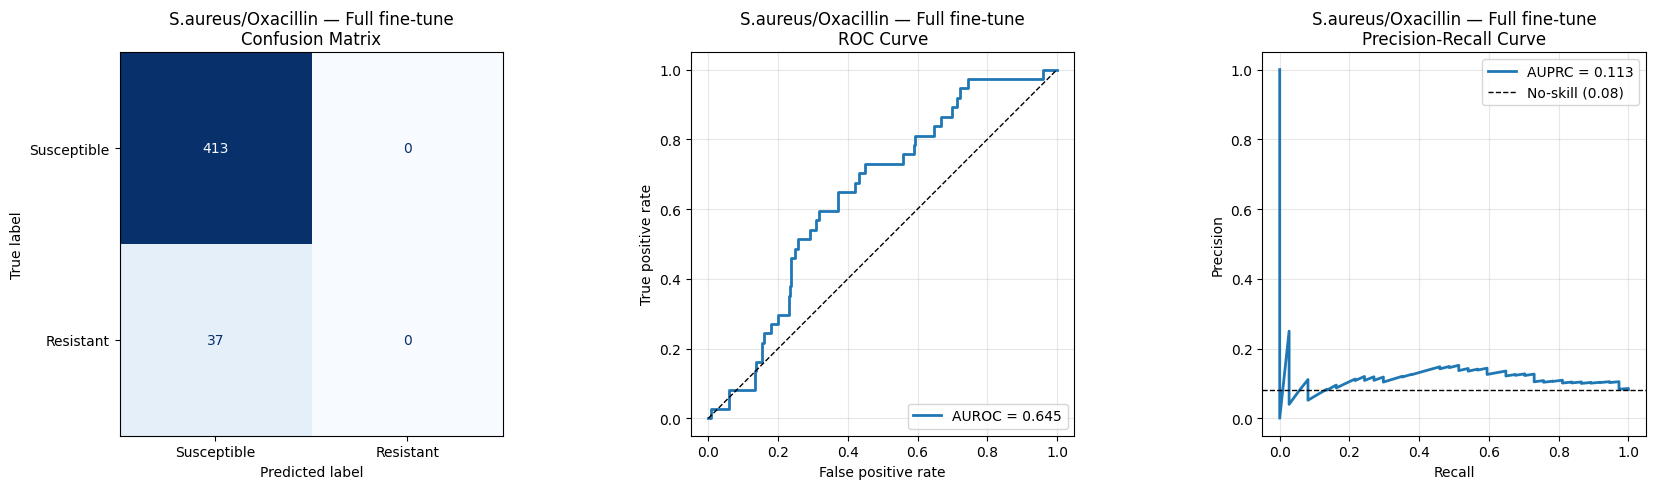

Saved: s_aureus_oxacillin_finetuned_full.h5


In [45]:
## Full fine-tune
print("--- Experiment 8-B: Full fine-tune ---")
sa_ft_full = finetune_full(MODELS['s_aureus_oxacillin'])
hist_sa_full = run_finetune(sa_ft_full, X_train_sa, y_train_sa, X_val_sa, y_val_sa)
plot_history(hist_sa_full, label='S.aureus/Oxacillin — Full fine-tune')

res = evaluate_model(sa_ft_full, X_test_sa, y_test_sa,
                     X_train_sa, y_train_sa,
                     label='S.aureus/Oxacillin — Full fine-tune')
res['model'] = 's_aureus_oxacillin'; res['experiment'] = 'Full fine-tune'
ALL_RESULTS.append(res)

sa_ft_full.save('s_aureus_oxacillin_finetuned_full.h5')
print("Saved: s_aureus_oxacillin_finetuned_full.h5")

--- Experiment 8-D: Partial unfreeze ---


Partial-unfreeze model — trainable: 14  frozen: 8
Epoch 1/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.8475 - auc: 0.6133 - fn: 59.0000 - fp: 97.0000 - loss: 1.2467 - prc: 0.1120 - precision: 0.1182 - recall: 0.1806 - tn: 854.0000 - tp: 13.0000 - val_accuracy: 0.9398 - val_auc: 0.1142 - val_fn: 2.0000 - val_fp: 3.0000 - val_loss: 0.9752 - val_prc: 0.0132 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 78.0000 - val_tp: 0.0000e+00 - learning_rate: 5.0000e-06
Epoch 2/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.8813 - auc: 0.5928 - fn: 29.0000 - fp: 39.0000 - loss: 0.9966 - prc: 0.1114 - precision: 0.1333 - recall: 0.1714 - tn: 499.0000 - tp: 6.0000 - val_accuracy: 0.9277 - val_auc: 0.1204 - val_fn: 2.0000 - val_fp: 4.0000 - val_loss: 0.9308 - val_prc: 0.0133 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_tn: 77.0000 - val_tp: 0.0000e+00 - learning_rate: 5.0000e-06
Epoch 3/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.9040 - auc:

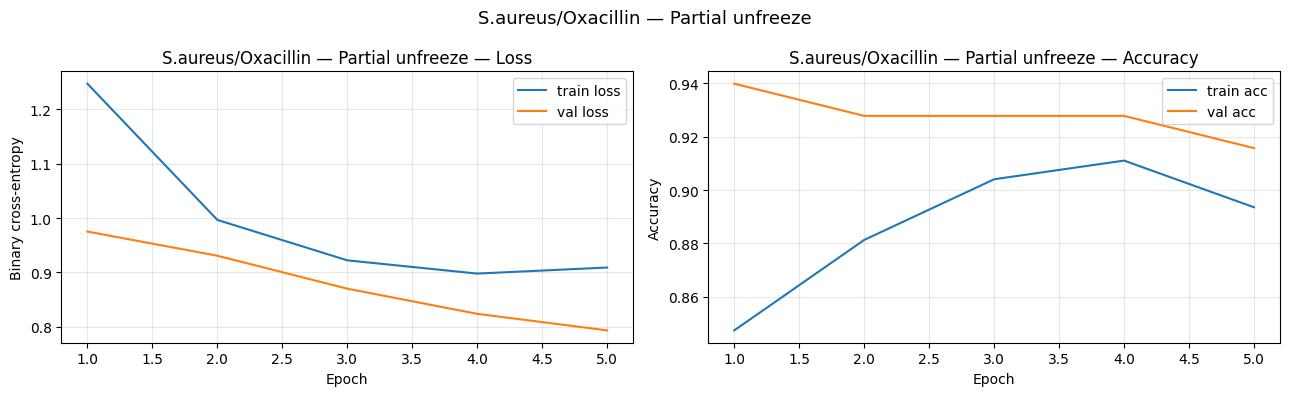

Confusion matrix:
[[413   0]
 [ 37   0]]

Balanced accuracy: 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.92      1.00      0.96       413
  Resistant (1)       0.00      0.00      0.00        37

       accuracy                           0.92       450
      macro avg       0.46      0.50      0.48       450
   weighted avg       0.84      0.92      0.88       450

Keras metrics (test set):
  loss: 0.9429
  compile_metrics: 0.0000

AUROC (sklearn): 0.6782
AUPRC (sklearn): 0.1201


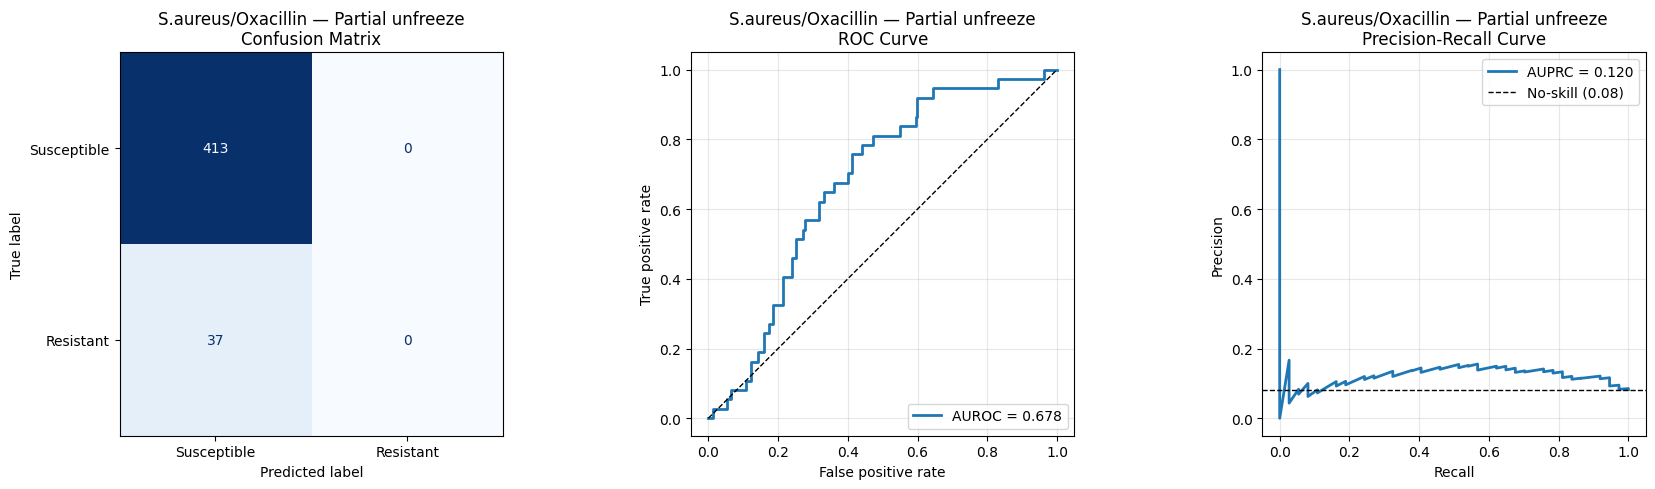

Saved: s_aureus_oxacillin_finetuned_partial.h5


In [47]:
## Partial Unfreeze
print("--- Experiment 8-D: Partial unfreeze ---")
sa_ft_partial = finetune_partial(MODELS['s_aureus_oxacillin'])
hist_sa_partial = run_finetune(sa_ft_partial, X_train_sa, y_train_sa, X_val_sa, y_val_sa)
plot_history(hist_sa_partial, label='S.aureus/Oxacillin — Partial unfreeze')

res = evaluate_model(sa_ft_partial, X_test_sa, y_test_sa,
                     X_train_sa, y_train_sa,
                     label='S.aureus/Oxacillin — Partial unfreeze')
res['model'] = 's_aureus_oxacillin'; res['experiment'] = 'Partial unfreeze'
ALL_RESULTS.append(res)

sa_ft_partial.save('s_aureus_oxacillin_finetuned_partial.h5')
print("Saved: s_aureus_oxacillin_finetuned_partial.h5")

## summary Comparison Table

All results collected here are presented in a single table

In [48]:
results_df = pd.DataFrame(ALL_RESULTS)

# Reorder columns for readability
col_order = ['model', 'experiment',
             'balanced_acc', 'accuracy', 'precision', 'recall',
             'auc', 'prc', 'auroc_sk', 'auprc_sk',
             'tp', 'fp', 'tn', 'fn']
results_df = results_df[[c for c in col_order if c in results_df.columns]]

print("Full results table:")
display(results_df.set_index(['model', 'experiment']))

# Save to CSV for external analysis
results_df.to_csv('finetune_results_summary.csv', index=False)
print("\nSaved to finetune_results_summary.csv")

Full results table:


balanced_acc  accuracy  precision  \
model                    experiment                                            
e_coli_ceftriaxone       Baseline                0.5000         0          0   
                         Full fine-tune          0.5273         0          0   
                         Baseline                0.5000         0          0   
                         Full fine-tune          0.5000         0          0   
                         Partial unfreeze        0.5000         0          0   
k_pneumoniae_ceftriaxone Baseline                0.5000         0          0   
                         Full fine-tune          0.5000         0          0   
                         Partial unfreeze        0.5000         0          0   
s_aureus_oxacillin       Baseline                0.5014         0          0   
                         Full fine-tune          0.5000         0          0   
                         Partial unfreeze        0.5000         0          0   

                                           recall  auc  prc  auroc_sk  \
model                    experiment                                     
e_coli_ceftriaxone       Baseline               0    0    0    0.6273   
                         Full fine-tune         0    0    0    0.6777   
                         Baseline               0    0    0    0.6273   
                         Full fine-tune         0    0    0    0.6323   
                         Partial unfreeze       0    0    0    0.6301   
k_pneumoniae_ceftriaxone Baseline               0    0    0    0.6995   
                         Full fine-tune         0    0    0    0.6955   
                         Partial unfreeze       0    0    0    0.6897   
s_aureus_oxacillin       Baseline               0    0    0    0.7032   
                         Full fine-tune         0    0    0    0.6450   
                         Partial unfreeze       0    0    0    0.6782   

                                           auprc_sk  tp  fp  tn  fn  
model                    experiment                                  
e_coli_ceftriaxone       Baseline            0.1784   0   0   0   0  
                         Full fine-tune      0.2404   0   0   0   0  
                         Baseline            0.1784   0   0   0   0  
                         Full fine-tune      0.1881   0   0   0   0  
                         Partial unfreeze    0.1878   0   0   0   0  
k_pneumoniae_ceftriaxone Baseline            0.1813   0   0   0   0  
                         Full fine-tune      0.1889   0   0   0   0  
                         Partial unfreeze    0.1810   0   0   0   0  
s_aureus_oxacillin       Baseline            0.1272   0   0   0   0  
                         Full fine-tune      0.1125   0   0   0   0  
                         Partial unfreeze    0.1201   0   0   0   0


Saved to finetune_results_summary.csv


### Visual Comparison -- AUROC across experiments and models

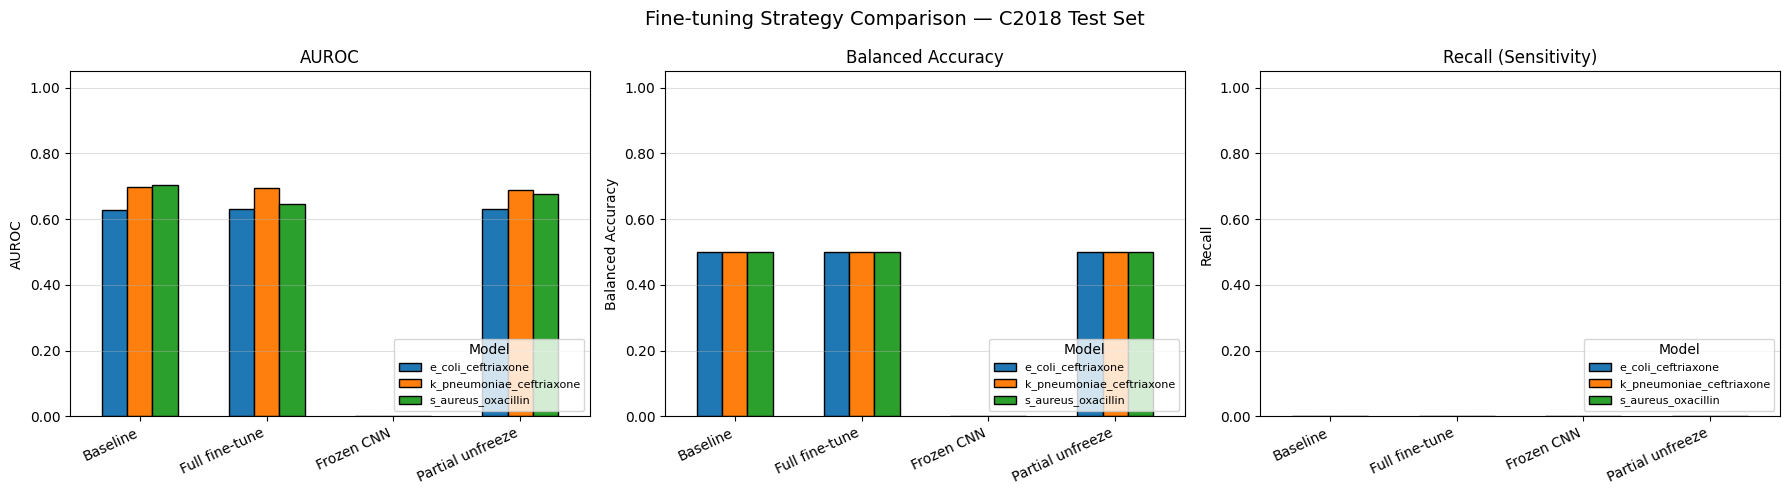

In [50]:
import matplotlib.ticker as mticker

results_df = results_df.drop_duplicates(subset=['experiment', 'model'], keep='last')

pivot_auc    = results_df.pivot(index='experiment', columns='model', values='auroc_sk')
pivot_bal    = results_df.pivot(index='experiment', columns='model', values='balanced_acc')
pivot_recall = results_df.pivot(index='experiment', columns='model', values='recall')

exp_order = ['Baseline', 'Full fine-tune', 'Frozen CNN', 'Partial unfreeze']
pivot_auc    = pivot_auc.reindex(exp_order)
pivot_bal    = pivot_bal.reindex(exp_order)
pivot_recall = pivot_recall.reindex(exp_order)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, pivot, title, ylabel in zip(
    axes,
    [pivot_auc, pivot_bal, pivot_recall],
    ['AUROC', 'Balanced Accuracy', 'Recall (Sensitivity)'],
    ['AUROC', 'Balanced Accuracy', 'Recall']
):
    pivot.plot(kind='bar', ax=ax, edgecolor='black', width=0.6)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    ax.set_xticklabels(pivot.index, rotation=25, ha='right')
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))
    ax.legend(title='Model', loc='lower right', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.4)

plt.suptitle('Fine-tuning Strategy Comparison — C2018 Test Set', fontsize=14)
plt.tight_layout()
plt.savefig('finetune_comparison_bars.png', bbox_inches='tight')
plt.show()

### Some necessary discussions and conclusion